# Residual Analysis: Single Energy Bin

This notebook demonstrates how to use `ResidualAnalysis` when the observed and expected histograms already contain one measured-energy (`Em`) bin. No energy selection is needed.

The workflow is:

1. Load matching observed and expected histograms.
2. Confirm that the input contains one `Em` bin.
3. Initialize `ResidualAnalysis` directly from those histograms.
4. Calculate a representative residual and generate its diagnostic plot.

## Setup

The following cells locate the `workflow` directory and import the histogram, residual-analysis, plotting, and display tools used in this notebook.

In [1]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)

# Make the local workflow modules importable.
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

from histpy import Histogram
from IPython.display import display
import h5py
import numpy as np

## Load the residual products

`ResidualAnalysis` requires an observed-count histogram and the corresponding fitted expected-count histogram. The two histograms must have identical axes and shapes, and their counts must be finite and non-negative.

This notebook uses `workflow/data/residual/03_511_imaging_residual_products.hdf5`. Repository notebook `03_511_imaging_analysis.ipynb` writes this file from its final DC4 image-deconvolution result: `fitted_image` and `fitted_background_norm` are used to calculate the source, background, and total expectations before the histograms are exported. It is therefore a stored fitted DC4 product, and this tutorial does not rerun the fit.

To analyze another result, change `residual_file` and, if necessary, the `name` values used to load `observed` and `expected`. HDF5 object names can differ between files, so inspect them before calling `Histogram.open()`.

In [3]:
# Locate the single-energy-bin residual product.
residual_dir = repo_root / "data" / "residual"
residual_file = residual_dir / "03_511_imaging_residual_products.hdf5"

print("Input file:", residual_file)
print("File exists:", residual_file.exists())

Input file: /Users/maura/Documents/COSI/data-challenge-4/workflow/data/residual/03_511_imaging_residual_products.hdf5
File exists: True


In [4]:
# Inspect the available objects before choosing histogram names.
with h5py.File(residual_file, "r") as residual_data:
    available_objects = list(residual_data.keys())

print("Available objects:", available_objects)

Available objects: ['background_expectation', 'observed', 'source_expectation', 'total_expectation']


In [5]:
# Load the observed counts and total fitted expectation.
# Replace these names if the previous cell reports different objects.
observed = Histogram.open(
    residual_file,
    name="observed",
)

expected = Histogram.open(
    residual_file,
    name="total_expectation",
)

### Verify the input structure

Inspect both histograms before initializing the analysis. This example must report one `Em` bin. If a file reports multiple bins, use the multi-energy tutorial instead.

In [6]:
# Confirm that both histograms have matching dimensions.
energy_bin_count = observed.axes["Em"].nbins

print("Observed axes:", observed.axes.labels)
print("Expected axes:", expected.axes.labels)
print("Observed shape:", observed.shape)
print("Expected shape:", expected.shape)
print("Number of Em bins:", energy_bin_count)
print("Em bin edges:", observed.axes["Em"].edges)

if energy_bin_count != 1:
    raise ValueError(
        "This tutorial requires an input containing exactly one Em bin."
    )

Observed axes: ['Em' 'Phi' 'PsiChi']
Expected axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (1, 60, 3072)
Expected shape: (1, 60, 3072)
Number of Em bins: 1
Em bin edges: [509. 513.] keV


## Initialize the analysis

Create the analysis directly from the matching histograms. This file already contains exactly one `Em` bin, so no energy-selection step is required. The stored expectation uses a known artificial floor of `1e-12`.

In [7]:
# No energy-selection step is needed for this input.
# This product uses a known artificial expected-count floor of 1e-12.
analysis = ResidualAnalysis(
    observed,
    expected,
    expected_floor=1e-12,
)

## Calculate a residual and generate a plot

At this point the data are loaded and `analysis` is initialized. A normal residual-analysis workflow now needs only three operations:

1. Calculate a residual histogram for a supported projection.
2. Initialize `PlottingResiduals` with the analysis object.
3. Request the same projection and residual definition from `plot()`.

The following cell uses raw residuals so the practical workflow has no simulation cost. It demonstrates the three principal visualization families: a 1D `Phi` diagnostic, paired rectangular `Phi-Chi` and `Phi-Psi` maps, and a Phi-integrated `PsiChi` HEALPix map. The direct residual variable is useful for numerical inspection or export; the plotter recalculates requested residuals internally and therefore does not receive that variable.

In [8]:
# Calculate one residual histogram for direct numerical use.
standard_phi_residual = analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

print("Residual axes:", standard_phi_residual.axes.labels)
print("Residual shape:", standard_phi_residual.shape)

Residual axes: ['Phi']
Residual shape: (60,)


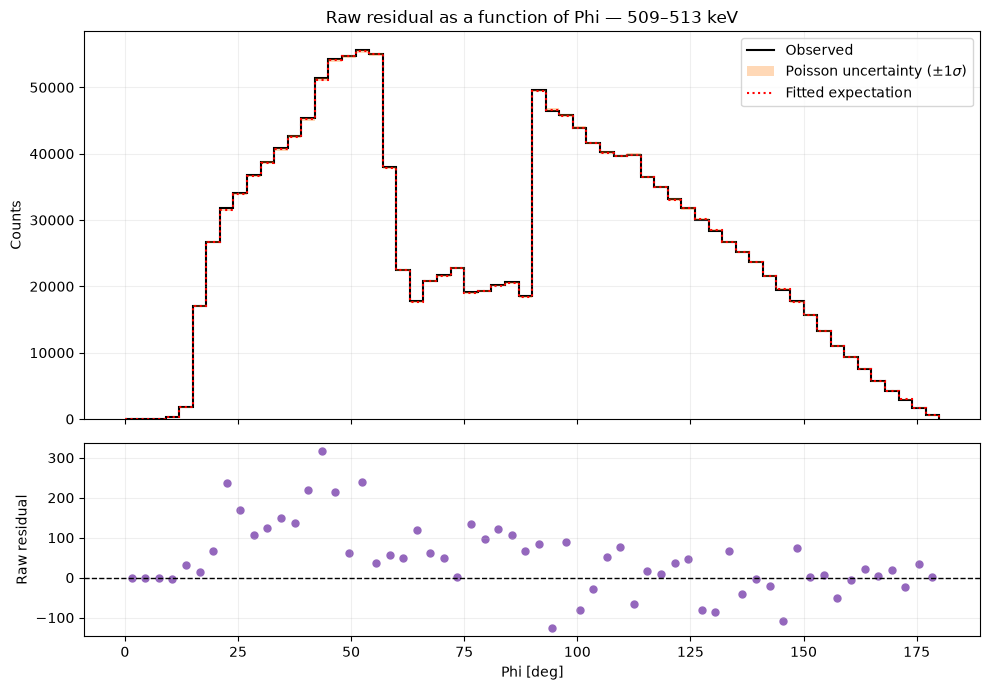

/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:1176: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


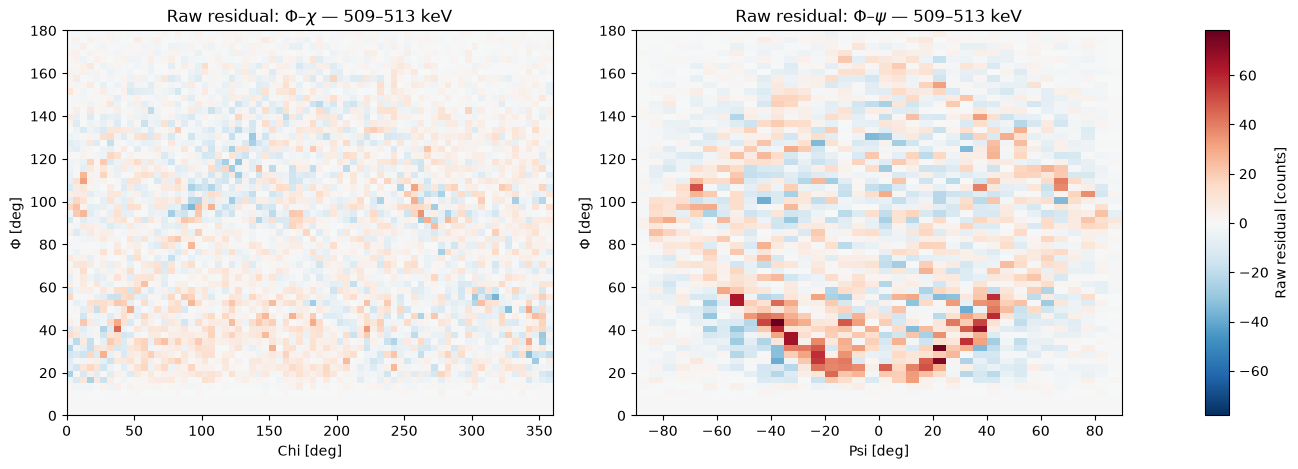

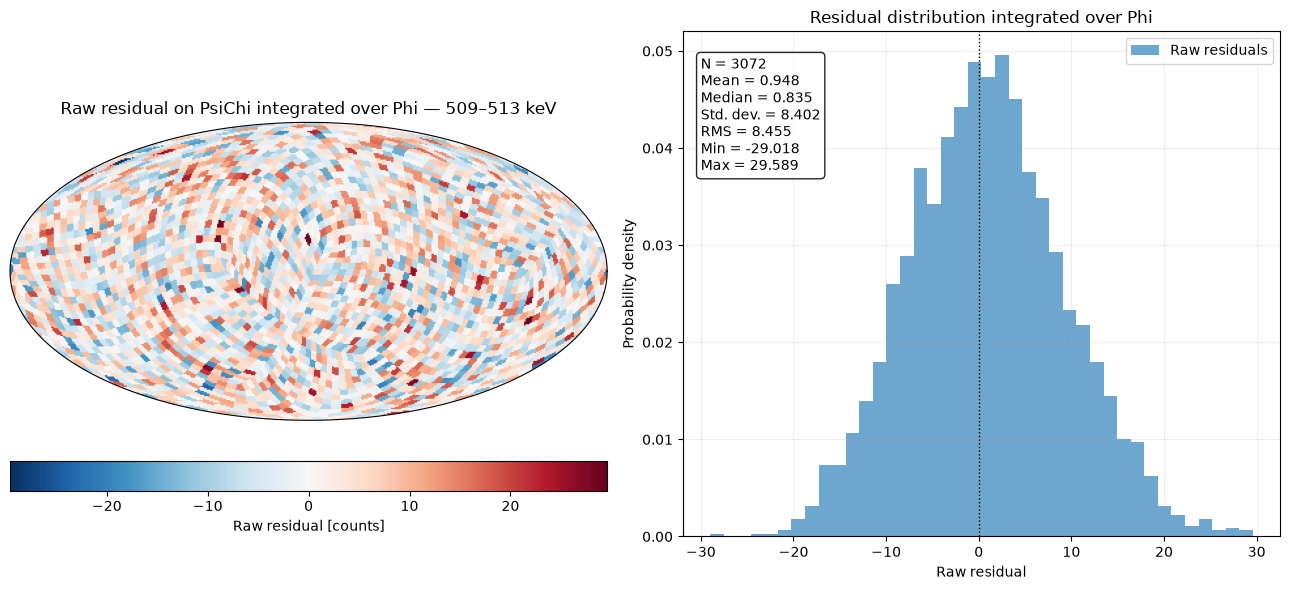

In [9]:
# Give the completed analysis object to the plotting interface.
standard_plotter = PlottingResiduals(analysis)

# Generate a representative one-dimensional diagnostic.
standard_phi_figure = standard_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# One rectangular request displays both Phi-Chi and Phi-Psi maps.
standard_angular_2d_figure = standard_plotter.plot(
    "Phi_Chi_projection",
    residual_type="raw",
)

# Display the PsiChi residual map integrated over Phi.
standard_psichi_figure = standard_plotter.plot(
    "PsiChi_projection",
    residual_type="raw",
)


### What the workflow produced

`standard_phi_residual` is a one-dimensional HistPy histogram containing observed-minus-expected counts in each `Phi` bin. Its plot reveals broad trends versus Compton-scatter angle. The paired rectangular maps show where residual structure depends jointly on `Phi` and either `Chi` or `Psi`. The HEALPix view preserves the full `PsiChi` geometry and reveals localized angular structure after integrating over `Phi`. Together these plots provide complementary views of the same masked observed and expected counts.

## Plot residual diagnostics

`n_simulations` enables fixed-fit Poisson reference distributions for Pearson residuals, and `random_seed` makes those simulations reproducible. Increase `n_simulations` for a smoother final reference.

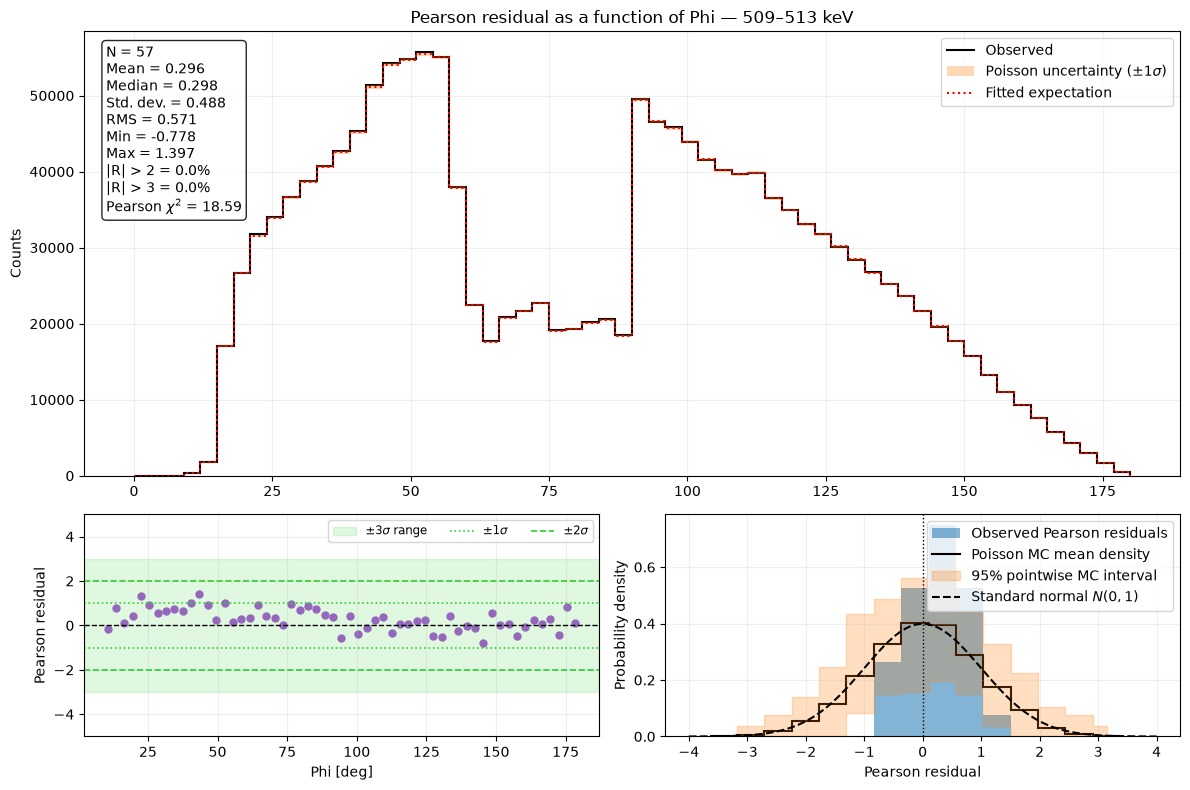

In [10]:
# Modify these values to control Monte Carlo cost and reproducibility.
n_simulations = 50
random_seed = 42

# Configure the plotter once and reuse it for this analysis object.
plotter = PlottingResiduals(
    analysis,
    n_simulations=n_simulations,
    random_seed=random_seed,
)

# Plot one representative one-dimensional CDS projection.
phi_figure = plotter.plot(
    "Phi_projection",
    residual_type="pearson",
    show_gaussian_reference=True,
)

### Paired rectangular projections

Requesting either `Phi_Chi_projection` or `Phi_Psi_projection` produces one figure containing both maps, with a shared color scale. The single call below is therefore sufficient to demonstrate both two-dimensional combinations.

/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:1176: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


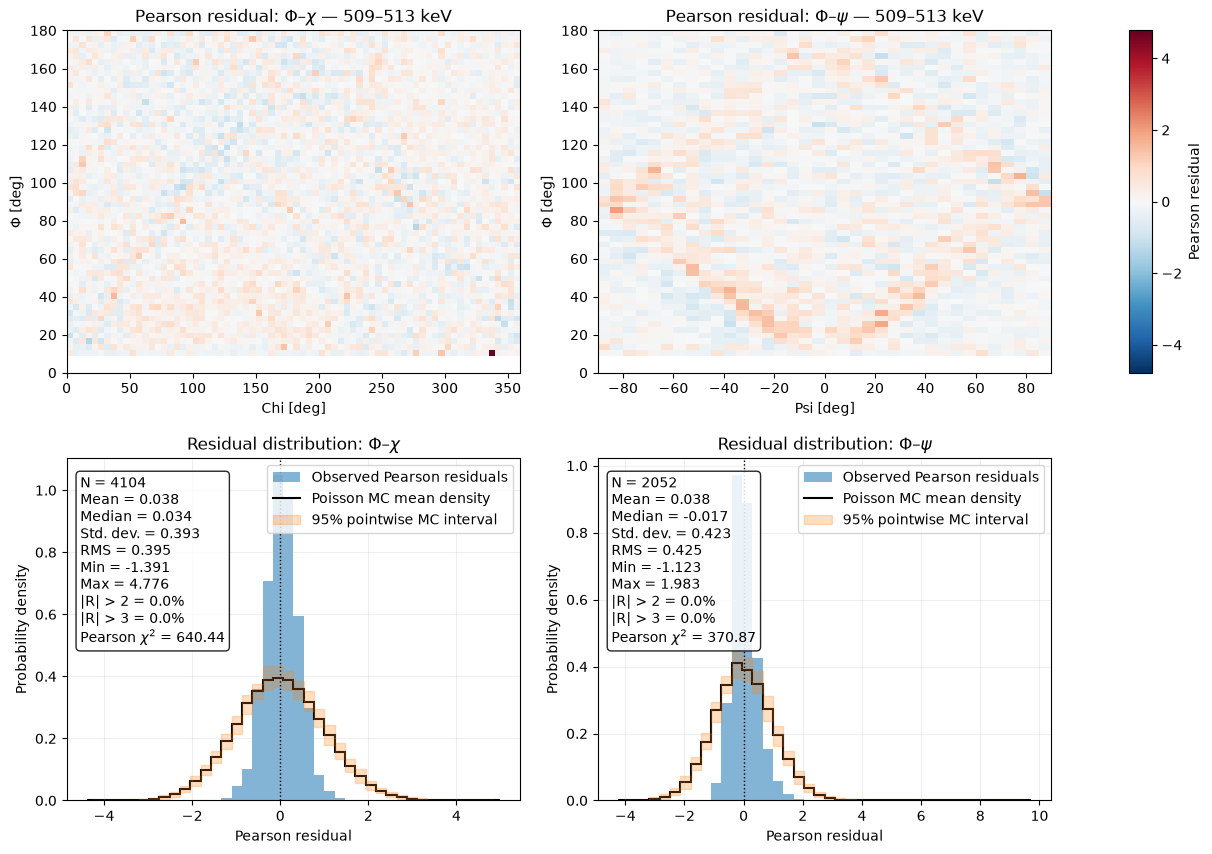

In [11]:
# One call displays the paired Phi-Chi and Phi-Psi diagnostics.
angular_2d_figure = plotter.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

## Display the statistics table

- **Notes:** This is a full-CDS summary, not a summary of the last plot. It does not calculate fitted degrees of freedom or a goodness-of-fit probability.

In [12]:
# Use "raw" or "fractional" for the other residual definitions.
display(analysis.statistics_table("pearson"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,175104,0.006482,-0.095382,0.456881,0.456927,-1.626413,17.35212,0.401476,0.223867,36558.590854,25525.814956
